In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, classification_report
)

bc = load_breast_cancer(as_frame=True)
bc_df = bc.frame.copy()

# In the original sklearn dataset: 0=malignant, 1=benign.
# Recode so the positive class (1) is malignant.
bc_df["malignant"] = (bc_df["target"] == 0).astype(int)
print("Rows:", bc_df.shape[0], "| Columns:", bc_df.shape[1])
display(bc_df.head())
print("Missing values:", bc_df.isna().sum().sum())
print("Duplicates:", bc_df.duplicated().sum())

selected_features = ["mean radius", "mean texture", "mean perimeter",
                     "mean area", "mean smoothness", "mean concavity"]
Xc = bc_df[selected_features]
yc = bc_df["malignant"]
display(yc.value_counts().rename(index={0:"Benign (0)",1:"Malignant (1)"}))

Rows: 569 | Columns: 32


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,1


Missing values: 0
Duplicates: 0


,count
malignant,
Benign (0),357
Malignant (1),212


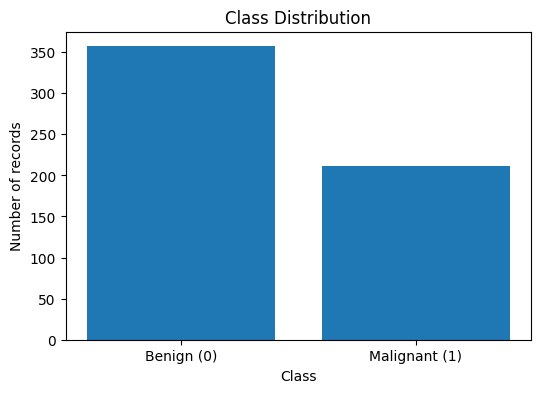

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268


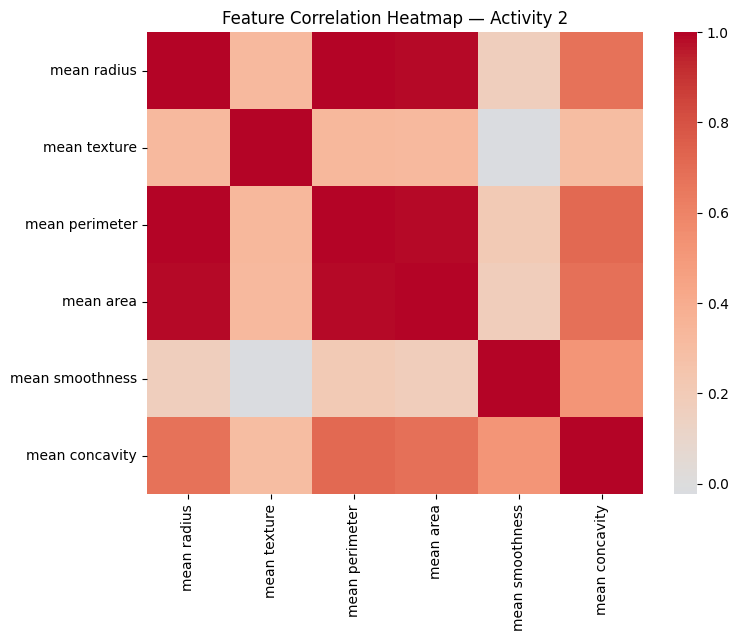

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Define RANDOM_STATE for consistency in subsequent steps
RANDOM_STATE = 42

counts = yc.value_counts().sort_index()
plt.figure(figsize=(6,4))
plt.bar(["Benign (0)", "Malignant (1)"], counts.values)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.show()

display(Xc.describe().T)
corr_c = Xc.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_c, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap — Activity 2")
plt.show()

In [17]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, random_state=RANDOM_STATE, stratify=yc
)
print("Training rows:", len(Xc_train), "| Test rows:", len(Xc_test))
print("Training class counts:")
display(yc_train.value_counts())
print("Test class counts:")
display(yc_test.value_counts())

log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
log_model.fit(Xc_train, yc_train)
print("Model trained.")

Training rows: 455 | Test rows: 114
Training class counts:


,count
malignant,
0,285
1,170


Test class counts:


,count
malignant,
0,72
1,42


Model trained.


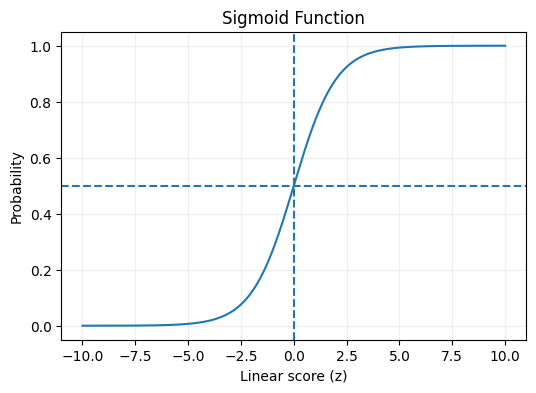

In [18]:
z = np.linspace(-10, 10, 300)
sigmoid = 1/(1+np.exp(-z))
plt.figure(figsize=(6,4))
plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.title("Sigmoid Function")
plt.xlabel("Linear score (z)")
plt.ylabel("Probability")
plt.grid(alpha=0.2)
plt.show()

In [19]:
lr = log_model.named_steps["logistic"]
coef_table = pd.DataFrame({"Feature": selected_features, "Coefficient (scaled)": lr.coef_[0]})
print("Intercept:", lr.intercept_[0])
display(coef_table.sort_values("Coefficient (scaled)", ascending=False))

prob_test = log_model.predict_proba(Xc_test)[:, 1]  # probability malignant
pred_05 = (prob_test >= 0.5).astype(int)
sample_predictions = pd.DataFrame({
    "Actual malignant (1)/benign (0)": yc_test.values,
    "Probability malignant": prob_test,
    "Predicted label at threshold 0.5": pred_05
}, index=yc_test.index)
display(sample_predictions.head(10))

Intercept: -0.5856658511114691


,Feature,Coefficient (scaled)
3,mean area,1.524698
4,mean smoothness,1.477489
1,mean texture,1.462226
0,mean radius,1.401136
2,mean perimeter,1.227983
5,mean concavity,1.203674


,Actual malignant (1)/benign (0),Probability malignant,Predicted label at threshold 0.5
120,0,0.000474,0
250,1,0.999994,1
375,0,0.564577,1
99,1,0.475378,0
455,0,0.725237,1
318,0,0.015544,0
39,1,0.460335,0
371,0,0.013163,0
98,0,0.000821,0
502,0,0.119720,0


In [20]:
def metrics_at_threshold(y_true, probs, threshold):
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    accuracy = accuracy_score(y_true, pred)
    precision = precision_score(y_true, pred, zero_division=0)
    recall = recall_score(y_true, pred, zero_division=0)
    specificity = tn/(tn+fp) if (tn+fp) else 0
    f1 = f1_score(y_true, pred, zero_division=0)
    return {"Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": accuracy, "Precision": precision, "Recall": recall,
            "Specificity": specificity, "F1-score": f1}

m05 = metrics_at_threshold(yc_test, prob_test, 0.5)
print("Confusion matrix at threshold 0.5 (rows actual 0/1, columns predicted 0/1):")
display(confusion_matrix(yc_test, pred_05, labels=[0,1]))
print("TN, FP, FN, TP:", m05["TN"], m05["FP"], m05["FN"], m05["TP"])
display(pd.DataFrame([m05]))
print("Classification report at threshold 0.5:")
print(classification_report(yc_test, pred_05, target_names=["Benign", "Malignant"], zero_division=0))
print("ROC-AUC:", roc_auc_score(yc_test, prob_test))

Confusion matrix at threshold 0.5 (rows actual 0/1, columns predicted 0/1):


array([[68,  4],
       [ 5, 37]])

TN, FP, FN, TP: 68 4 5 37


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,Specificity,F1-score
0,0.5,68,4,5,37,0.921053,0.902439,0.880952,0.944444,0.891566


Classification report at threshold 0.5:
              precision    recall  f1-score   support

      Benign       0.93      0.94      0.94        72
   Malignant       0.90      0.88      0.89        42

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114

ROC-AUC: 0.9821428571428571


In [21]:
majority_class = yc_train.value_counts().idxmax()
baseline_pred = np.full(len(yc_test), majority_class)
baseline = {
    "Accuracy": accuracy_score(yc_test, baseline_pred),
    "Precision": precision_score(yc_test, baseline_pred, zero_division=0),
    "Recall": recall_score(yc_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(yc_test, baseline_pred, zero_division=0)
}
model_05 = {k: m05[k] for k in ["Accuracy", "Precision", "Recall", "F1-score"]}
display(pd.DataFrame({"Majority baseline": baseline, "Logistic Regression (0.5)": model_05}).T)

,Accuracy,Precision,Recall,F1-score
Majority baseline,0.631579,0.000000,0.000000,0.000000
Logistic Regression (0.5),0.921053,0.902439,0.880952,0.891566


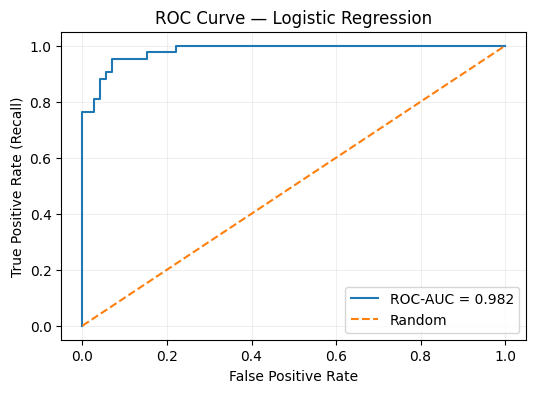

ROC-AUC: 0.9821428571428571


In [22]:
fpr, tpr, roc_thresholds = roc_curve(yc_test, prob_test)
auc_value = roc_auc_score(yc_test, prob_test)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc_value:.3f}")
plt.plot([0,1], [0,1], "--", label="Random")
plt.title("ROC Curve — Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print("ROC-AUC:", auc_value)

In [23]:
threshold_results = pd.DataFrame([metrics_at_threshold(yc_test, prob_test, t) for t in [0.3,0.5,0.7]])
display(threshold_results[["Threshold", "TN", "FP", "FN", "TP", "Accuracy", "Precision", "Recall", "Specificity", "F1-score"]])

plt.figure(figsize=(6,4))
for t in [0.3,0.5,0.7]:
    p = (prob_test >= t).astype(int)
    print(f"Threshold {t}: predicted malignant =", int(p.sum()))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,Specificity,F1-score
0,0.3,65,7,2,40,0.921053,0.851064,0.952381,0.902778,0.898876
1,0.5,68,4,5,37,0.921053,0.902439,0.880952,0.944444,0.891566
2,0.7,69,3,8,34,0.903509,0.918919,0.809524,0.958333,0.860759


Threshold 0.3: predicted malignant = 47
Threshold 0.5: predicted malignant = 41
Threshold 0.7: predicted malignant = 37


<Figure size 600x400 with 0 Axes>

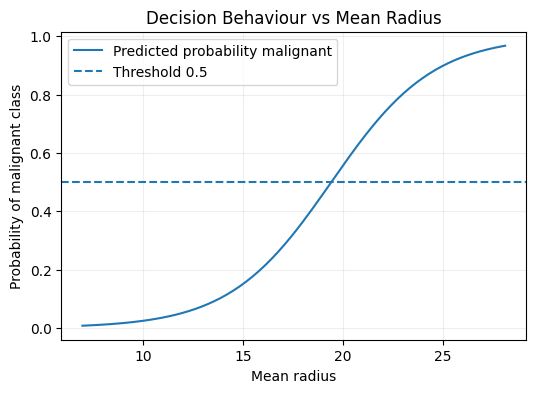

In [24]:
radius_grid = np.linspace(Xc_train["mean radius"].min(), Xc_train["mean radius"].max(), 200)
fixed = Xc_train.median()
grid_df = pd.DataFrame({f: fixed[f] for f in selected_features}, index=range(len(radius_grid)))
grid_df["mean radius"] = radius_grid
grid_probs = log_model.predict_proba(grid_df)[:,1]

plt.figure(figsize=(6,4))
plt.plot(radius_grid, grid_probs, label="Predicted probability malignant")
plt.axhline(0.5, linestyle="--", label="Threshold 0.5")
plt.title("Decision Behaviour vs Mean Radius")
plt.xlabel("Mean radius")
plt.ylabel("Probability of malignant class")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [25]:
new_case = Xc_train.median().to_frame().T
new_prob = log_model.predict_proba(new_case)[0,1]
recommended_threshold = 0.3  # screening-style example prioritising sensitivity
new_label = int(new_prob >= recommended_threshold)
print("New example feature values:")
display(new_case)
print(f"Estimated probability malignant: {new_prob:.4f}")
print(f"Predicted label at threshold {recommended_threshold}:",
      "Malignant (1)" if new_label == 1 else "Benign (0)")

New example feature values:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean concavity
0,13.34,18.9,86.18,546.4,0.09524,0.0594


Estimated probability malignant: 0.0845
Predicted label at threshold 0.3: Benign (0)
